# Employee Attrition: Modeling

**Goal:** Predict which employees are at risk of attrition before they resign, enabling HR leadership to intervene early with high-impact, proactive retention strategies.

**Plan:**
1. **Load, clean and split the data (stratified 70 / 15 / 15)**: Verify clean features and establish strictly isolated training, validation, and test sets.
2. **Train three models in a `for` loop**:
   - **Logistic Regression (Baseline)**: Interpretable linear model with robust feature scaling and balanced class weights.
   - **Random Forest**: Non-linear ensemble model with tree-level subsampling.
   - **XGBoost**: Gradient boosted decision trees with shallow depth and positive class weighting.
3. **Compare candidates on the validation set**:
   - Evaluate across PR-AUC, ROC-AUC, F1-Score, Recall, and Precision.
   - Tune decision thresholds ($T^*$) on the validation set to balance precision vs. recall.
   - Plot Precision-Recall curves and metric comparison charts.
4. **Pick the best model and evaluate it once on the holdout test set**:
   - Evaluate champion model on unseen test data.
   - Plot confusion matrix and interpret risk drivers using Odds Ratios.

## 1. Imports, Settings & Environment Setup

In [ ]:
import sys
import os
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocess import (
    DATA_PATH,
    TARGET,
    build_preprocessing_pipeline,
    clean_data,
    split_data,
)

SEED = 42
MODELS_PATH = ROOT / "models"
FIGURES_DIR = ROOT / "reports" / "figures"
MODELS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load, Clean, and Stratified Split (70 / 15 / 15)

In [28]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Raw data shape: {raw_df.shape}")

clean_df = clean_data(raw_df)
print(f"Cleaned data shape: {clean_df.shape}")

X_train, X_val, X_test, y_train, y_val, y_test = split_data(
    clean_df, train_size=0.70, val_size=0.15, test_size=0.15, seed=SEED
)

split_summary = pd.DataFrame([
    {"Split": "Train", "Samples": len(y_train), "Attritions": int(y_train.sum()), "Attrition Rate": float(y_train.mean())},
    {"Split": "Validation", "Samples": len(y_val), "Attritions": int(y_val.sum()), "Attrition Rate": float(y_val.mean())},
    {"Split": "Test", "Samples": len(y_test), "Attritions": int(y_test.sum()), "Attrition Rate": float(y_test.mean())},
])
display(split_summary)

Raw data shape: (1470, 35)
Cleaned data shape: (1470, 31)


,Split,Samples,Attritions,Attrition Rate
0,Train,1029,166,0.1613
1,Validation,220,35,0.1591
2,Test,221,36,0.1629


## 3. Candidate Model Pipelines & Class Imbalance Strategy

In [29]:
neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
scale_pos_weight = round(neg_count / pos_count, 2)
print(f"Training Class Distribution: Retained (0) = {neg_count} | Attrited (1) = {pos_count}")
print(f"Computed scale_pos_weight = {scale_pos_weight:.2f}")

candidate_models = {
    "Logistic Regression": Pipeline(steps=[
        ("pre", build_preprocessing_pipeline(scale=True)),
        ("model", LogisticRegression(
            C=0.1,
            class_weight="balanced",
            max_iter=1000,
            random_state=SEED
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("pre", build_preprocessing_pipeline(scale=False)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=SEED
        ))
    ]),
    "XGBoost": Pipeline(steps=[
        ("pre", build_preprocessing_pipeline(scale=False)),
        ("model", XGBClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            reg_lambda=5.0,
            scale_pos_weight=scale_pos_weight,
            tree_method="hist",
            eval_metric="aucpr",
            n_jobs=-1,
            random_state=SEED
        ))
    ])
}

Training Class Distribution: Retained (0) = 863 | Attrited (1) = 166
Computed scale_pos_weight = 5.20


## 4. Train Models in a Loop & Compare on Validation Set

In [30]:
val_metrics_list = []
fitted_pipelines = {}
optimal_thresholds = {}
val_predictions = {}

for name, pipeline in candidate_models.items():
    print(f"Training [{name}]...")
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    
    y_val_probs = pipeline.predict_proba(X_val)[:, 1]
    val_predictions[name] = y_val_probs
    
    precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_probs)
    f1_scores = (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
    best_idx = int(np.argmax(f1_scores))
    best_thresh = float(thresholds[best_idx])
    optimal_thresholds[name] = best_thresh
    
    y_val_pred = (y_val_probs >= best_thresh).astype(int)
    
    val_metrics_list.append({
        "Model": name,
        "PR-AUC": float(average_precision_score(y_val, y_val_probs)),
        "ROC-AUC": float(roc_auc_score(y_val, y_val_probs)),
        "Optimal Threshold": round(best_thresh, 4),
        "F1-Score": float(f1_score(y_val, y_val_pred, zero_division=0)),
        "Recall": float(recall_score(y_val, y_val_pred, zero_division=0)),
        "Precision": float(precision_score(y_val, y_val_pred, zero_division=0))
    })

val_comparison_df = pd.DataFrame(val_metrics_list).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)
display(val_comparison_df)

Training [Logistic Regression]...
Training [Random Forest]...
Training [XGBoost]...


,Model,PR-AUC,ROC-AUC,Optimal Threshold,F1-Score,Recall,Precision
0,Logistic Regression,0.5492,0.8091,0.7026,0.5556,0.4286,0.7895
1,XGBoost,0.4285,0.7490,0.5289,0.4941,0.6000,0.4200
2,Random Forest,0.3284,0.7288,0.4406,0.5250,0.6000,0.4667


### 4.1 Precision-Recall Curves & Candidate Comparison

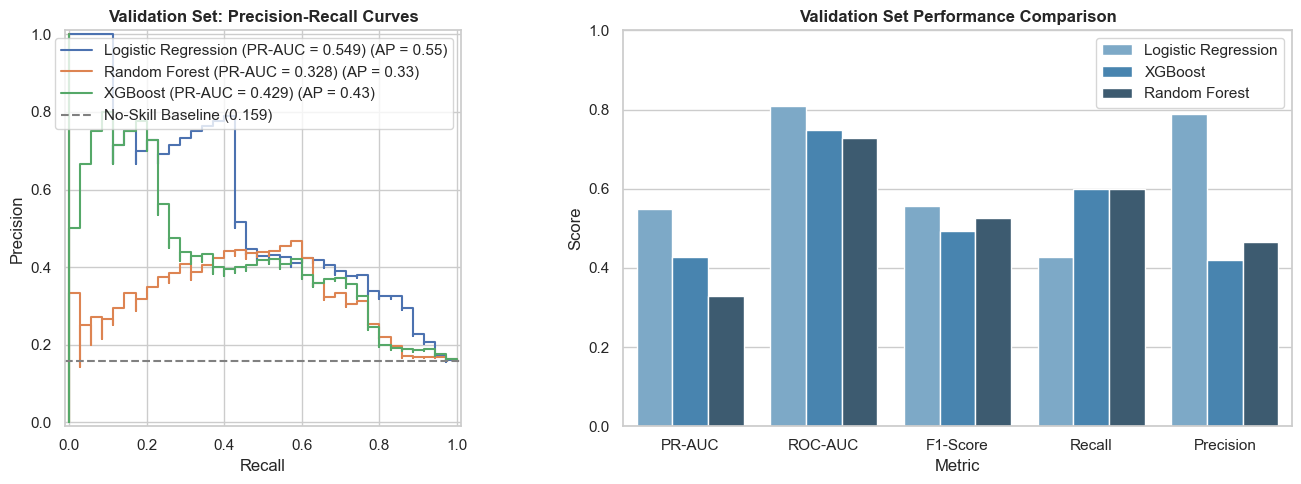

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
for name, probs in val_predictions.items():
    pr_auc = average_precision_score(y_val, probs)
    PrecisionRecallDisplay.from_predictions(
        y_val, probs, ax=ax1, name=f"{name} (PR-AUC = {pr_auc:.3f})"
    )
ax1.axhline(y_val.mean(), color="grey", linestyle="--", label=f"No-Skill Baseline ({y_val.mean():.3f})")
ax1.set_title("Validation Set: Precision-Recall Curves", fontsize=12, fontweight="bold")
ax1.set_xlabel("Recall")
ax1.set_ylabel("Precision")
ax1.legend(loc="upper right")

ax2 = axes[1]
melted = val_comparison_df.melt(id_vars="Model", value_vars=["PR-AUC", "ROC-AUC", "F1-Score", "Recall", "Precision"])
sns.barplot(data=melted, x="variable", y="value", hue="Model", palette="Blues_d", ax=ax2)
ax2.set_title("Validation Set Performance Comparison", fontsize=12, fontweight="bold")
ax2.set_xlabel("Metric")
ax2.set_ylabel("Score")
ax2.set_ylim(0, 1.0)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_model_comparison_metrics.png", dpi=150)
plt.show()

### 4.2 Decision Threshold Tuning Analysis

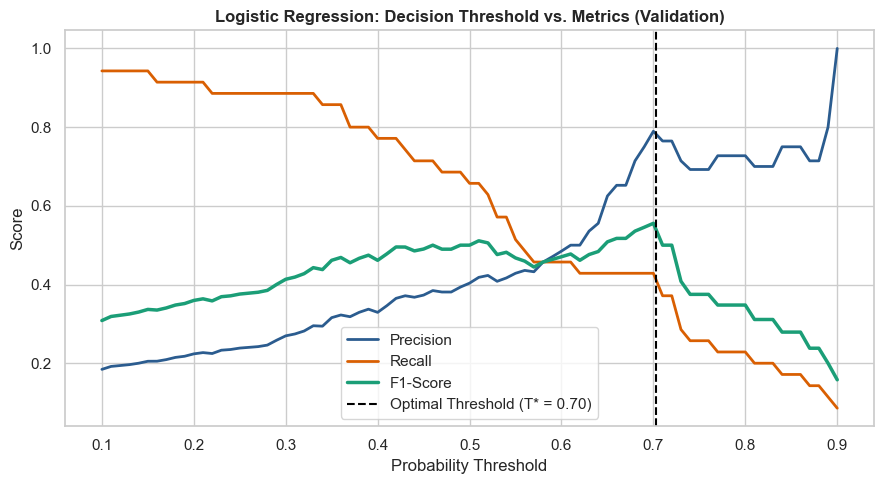

In [32]:
champion_name = "Logistic Regression"
champ_pipe = fitted_pipelines[champion_name]
champ_val_probs = val_predictions[champion_name]

t_range = np.linspace(0.10, 0.90, 81)
prec_list, rec_list, f1_list = [], [], []

for t in t_range:
    preds = (champ_val_probs >= t).astype(int)
    prec_list.append(precision_score(y_val, preds, zero_division=0))
    rec_list.append(recall_score(y_val, preds, zero_division=0))
    f1_list.append(f1_score(y_val, preds, zero_division=0))

best_t = optimal_thresholds[champion_name]

plt.figure(figsize=(9, 5))
plt.plot(t_range, prec_list, label="Precision", color="#2b5c8f", lw=2)
plt.plot(t_range, rec_list, label="Recall", color="#d95f02", lw=2)
plt.plot(t_range, f1_list, label="F1-Score", color="#1b9e77", lw=2.5)
plt.axvline(best_t, color="black", linestyle="--", label=f"Optimal Threshold (T* = {best_t:.2f})")
plt.title(f"{champion_name}: Decision Threshold vs. Metrics (Validation)", fontsize=12, fontweight="bold")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_decision_threshold_tuning.png", dpi=150)
plt.show()

## 5. Champion Model Selection & Final Holdout Test Set Evaluation

,Model,Split,Threshold,PR-AUC,ROC-AUC,F1-Score,Recall,Precision
0,Logistic Regression,Holdout Test,0.7000,0.6039,0.8455,0.5915,0.5833,0.6000



CLASSIFICATION REPORT (Holdout Test @ Threshold = 0.7)
              precision    recall  f1-score   support

Retained (0)       0.92      0.92      0.92       185
Attrited (1)       0.60      0.58      0.59        36

    accuracy                           0.87       221
   macro avg       0.76      0.75      0.76       221
weighted avg       0.87      0.87      0.87       221



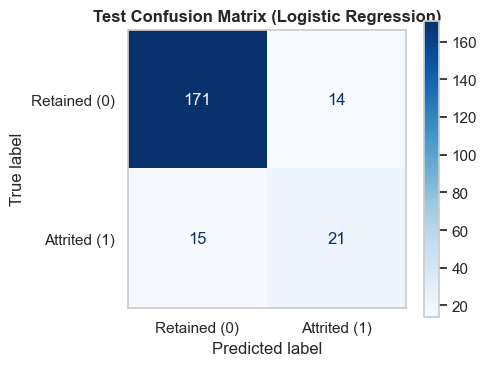

In [33]:
champion_thresh = round(optimal_thresholds[champion_name], 2)
test_probs = champ_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= champion_thresh).astype(int)

test_pr_auc = float(average_precision_score(y_test, test_probs))
test_roc_auc = float(roc_auc_score(y_test, test_probs))
test_f1 = float(f1_score(y_test, test_pred, zero_division=0))
test_recall = float(recall_score(y_test, test_pred, zero_division=0))
test_precision = float(precision_score(y_test, test_pred, zero_division=0))

test_summary_df = pd.DataFrame([{
    "Model": champion_name,
    "Split": "Holdout Test",
    "Threshold": champion_thresh,
    "PR-AUC": test_pr_auc,
    "ROC-AUC": test_roc_auc,
    "F1-Score": test_f1,
    "Recall": test_recall,
    "Precision": test_precision,
}])
display(test_summary_df)

print("\n" + "=" * 60)
print(f"CLASSIFICATION REPORT (Holdout Test @ Threshold = {champion_thresh})")
print("=" * 60)
print(classification_report(y_test, test_pred, target_names=["Retained (0)", "Attrited (1)"]))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["Retained (0)", "Attrited (1)"],
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title(f"Test Confusion Matrix ({champion_name})", fontweight="bold")
plt.grid(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_test_confusion_matrix.png", dpi=150)
plt.show()

## 6. Interpretability & Risk Factor Analysis (Odds Ratios)

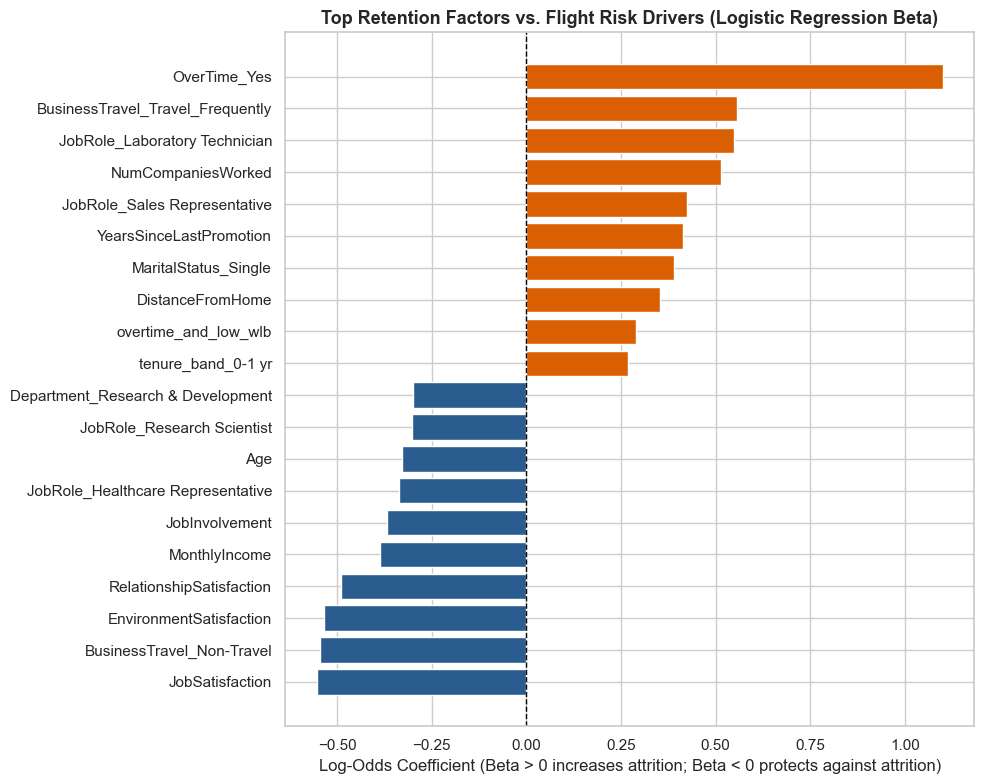


Top 5 Flight Risk Drivers (Highest Odds Ratios):


,Feature,Odds Ratio,Coefficient (Beta)
52,OverTime_Yes,3.0034,1.0997
28,BusinessTravel_Travel_Frequently,1.7434,0.5558
42,JobRole_Laboratory Technician,1.7330,0.5499
11,NumCompaniesWorked,1.6736,0.5150
48,JobRole_Sales Representative,1.5274,0.4236



Top 5 Protective Retention Factors (Lowest Odds Ratios):


,Feature,Odds Ratio,Coefficient (Beta)
31,Department_Research & Development,0.7416,-0.2990
46,JobRole_Research Scientist,0.7402,-0.3008
0,Age,0.7211,-0.3270
40,JobRole_Healthcare Representative,0.7146,-0.3360
6,JobInvolvement,0.6926,-0.3673


In [34]:
pre_transformer = champ_pipe.named_steps["pre"]
clf_estimator = champ_pipe.named_steps["model"]

col_transformer = pre_transformer.named_steps.get("preprocessor", pre_transformer) if hasattr(pre_transformer, "named_steps") else pre_transformer
feature_names = [
    f.replace("num__", "").replace("cat__", "").replace("bin__", "")
    for f in col_transformer.get_feature_names_out()
]
coefs = clf_estimator.coef_[0]
odds_ratios = np.exp(coefs)

feat_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient (Beta)": coefs,
    "Odds Ratio": odds_ratios
}).sort_values(by="Coefficient (Beta)", ascending=False)

# Top risk drivers & protective factors
top_risk = feat_imp_df.head(10)
top_protective = feat_imp_df.tail(10)
plot_df = pd.concat([top_risk, top_protective]).sort_values(by="Coefficient (Beta)", ascending=True)

plt.figure(figsize=(10, 8))
colors = ["#2b5c8f" if b < 0 else "#d95f02" for b in plot_df["Coefficient (Beta)"]]
bars = plt.barh(plot_df["Feature"], plot_df["Coefficient (Beta)"], color=colors)
plt.axvline(0, color="black", linestyle="--", lw=1)
plt.title("Top Retention Factors vs. Flight Risk Drivers (Logistic Regression Beta)", fontsize=13, fontweight="bold")
plt.xlabel("Log-Odds Coefficient (Beta > 0 increases attrition; Beta < 0 protects against attrition)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "14_feature_importance.png", dpi=150)
plt.show()

print("\nTop 5 Flight Risk Drivers (Highest Odds Ratios):")
display(top_risk.head(5)[["Feature", "Odds Ratio", "Coefficient (Beta)"]])

print("\nTop 5 Protective Retention Factors (Lowest Odds Ratios):")
display(top_protective.head(5)[["Feature", "Odds Ratio", "Coefficient (Beta)"]])